# 2. Modelación
Consume el split **processed** generado al cierre de `1_EDA` (`data/processed/train|test`); no divide ni transforma datos. Entrena y evalúa los modelos con las semillas fijadas (random_state=42) y complementa los resultados con métricas adicionales (precision, PR-AUC, umbral, recall por género, importancia y K-Means).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")

# Los .py y data/ viven en la raíz del proyecto: si el notebook corre desde notebooks/, subimos un nivel
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
os.makedirs(os.path.join("output", "graficos"), exist_ok=True)

In [ ]:
from src.pipeline import verificar_processed
from src.train import run as run_train

verificar_processed()   # Modelación no divide ni transforma: solo consume data/processed

print("Ejecutando Modelamiento (Semillas Reproducibles)...")
res_train = run_train()


[pipeline] data/processed disponible.
Ejecutando Modelamiento (Semillas Reproducibles)...
TRAIN - Entrenamiento de modelos supervisados
[train] X_train: (71706, 128) | Hit rate train: 21.0%

[train] Entrenando: Regresion Logistica ...
  AUC CV: 0.8380 | Gap CV: 0.0026 | 67.2s

[train] Entrenando: Random Forest ...
  AUC CV: 0.8217 | Gap CV: 0.0203 | 142.5s

[train] Entrenando: HistGradientBoosting ...
  AUC CV: 0.8561 | Gap CV: 0.0284 | 56.5s

                      auc_cv  auc_train_cv  gap_auc_cv   f1_cv  recall_cv  precision_cv
Regresion Logistica   0.8380        0.8407      0.0026  0.5638     0.8057        0.4336
Random Forest         0.8217        0.8419      0.0203  0.5392     0.7381        0.4250
HistGradientBoosting  0.8561        0.8846      0.0284  0.5686     0.8245        0.4340

[train] Mejor modelo por AUC en CV: HistGradientBoosting
[train] Ablacion de genero sobre HistGradientBoosting ...
[train] AUC CV con genero: 0.8561 | sin genero: 0.6946 | aporte: +0.1616


## 1. Comparación de modelos en test
Además del AUC se reportan precision, F1 y PR-AUC: con `class_weight="balanced"` el recall sube a costa de la precisión, y mostrar solo el recall haría ver el resultado mejor de lo que es.

In [3]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score
from src.pipeline import FEATURES_SCALE
from src.test import run as run_test
from src.metricas import tabla_comparativa, verificar_kpis
from src import graficos as gr

X_train = pd.read_csv("data/processed/train/X_train.csv")
X_test = pd.read_csv("data/processed/test/X_test.csv")
y_test = pd.read_csv("data/processed/test/y_test.csv").squeeze()
raw_test = pd.read_csv("data/raw/test/raw_test.csv")   # mismo orden que X_test

# La evaluación final (AUC, precision, recall, F1, PR-AUC, gap, lift y KPIs) vive solo en src/test.py;
# aquí se reutiliza su resultado, que también deja resultados_test.csv y kpis_cumplidos.csv.
res = run_test()
modelos = {n: joblib.load(os.path.join("output", "modelos", n.lower().replace(" ", "_") + ".joblib")) for n in res}

tabla = tabla_comparativa(res)
print(f"Test: {len(y_test):,} canciones | hit rate base: {y_test.mean():.3f} (= PR-AUC de un modelo al azar)")
tabla

TEST — Evaluacion final en conjunto de prueba
[test] Regresion Logistica: AUC=0.8357 | PR-AUC=0.5620 | Precision=0.4216 | Recall=0.7977 | Lift@10%=3.01
[test] Random Forest: AUC=0.8255 | PR-AUC=0.5736 | Precision=0.4173 | Recall=0.7574 | Lift@10%=3.19
[test] HistGradientBoosting: AUC=0.8569 | PR-AUC=0.6193 | Precision=0.4254 | Recall=0.8331 | Lift@10%=3.36

                      Accuracy  Precision  Recall  F1-Score  AUC-ROC  PR-AUC  AUC train  Gap AUC  Lift @10% Sobreajuste
Modelo                                                                                                                 
Regresion Logistica     0.7338     0.4216  0.7977    0.5516   0.8357  0.5620     0.8404   0.0047       3.01          No
Random Forest           0.7331     0.4173  0.7574    0.5381   0.8255  0.5736     0.8409   0.0153       3.19          No
HistGradientBoosting    0.7347     0.4254  0.8331    0.5632   0.8569  0.6193     0.8824   0.0255       3.36          No

KPIs de negocio:
KPI                  A

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,PR-AUC,AUC train,Gap AUC,Lift @10%,Sobreajuste
Modelo,,,,,,,,,,
Regresion Logistica,0.7338,0.4216,0.7977,0.5516,0.8357,0.5620,0.8404,0.0047,3.01,No
Random Forest,0.7331,0.4173,0.7574,0.5381,0.8255,0.5736,0.8409,0.0153,3.19,No
HistGradientBoosting,0.7347,0.4254,0.8331,0.5632,0.8569,0.6193,0.8824,0.0255,3.36,No


In [4]:
kpis = verificar_kpis(res)
kpi = kpis.pivot(index="Modelo", columns="KPI", values="Cumple")
kpi["Cumple todos"] = (kpis.assign(ok=kpis["Cumple"] == "Si").groupby("Modelo")["ok"].all()
                       .map({True: "Si", False: "No"}))
kpi

KPI,AUC-ROC,Gap AUC,Lift @10%,Recall,Cumple todos
Modelo,,,,,
HistGradientBoosting,Si,Si,Si,Si,Si
Random Forest,Si,Si,Si,Si,Si
Regresion Logistica,Si,Si,Si,Si,Si


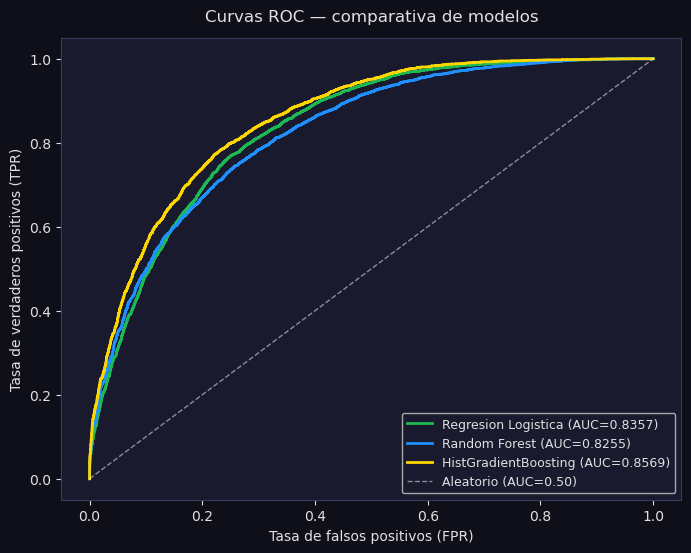

[graficos] Guardado: output\graficos\08_curvas_roc.png


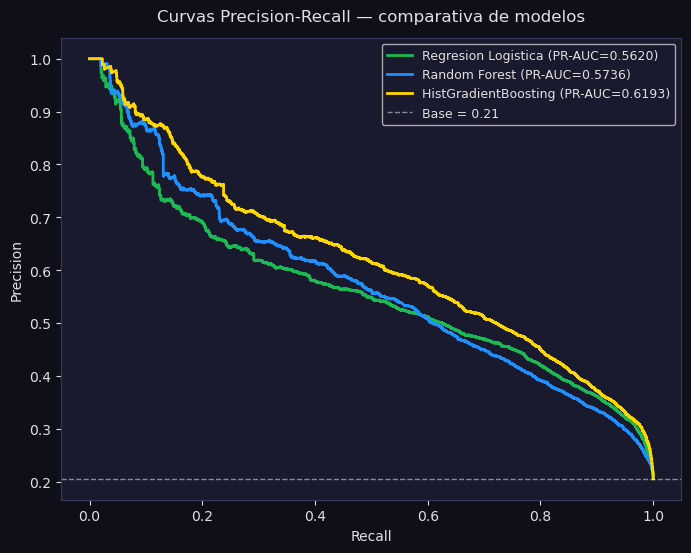

[graficos] Guardado: output\graficos\09_curvas_pr.png


In [5]:
gr.grafico_roc(res, y_test)
gr.grafico_pr(res, y_test)

## 2. Efecto del umbral de decisión
El recall depende del umbral. Con `class_weight="balanced"` el umbral 0.5 favorece el recall y deja pasar muchos falsos positivos. Esta tabla muestra el compromiso para el mejor modelo.

In [6]:
cv = pd.read_csv(os.path.join("output", "modelos", "resultados_cv.csv"), index_col=0)
mejor = res_train["mejor"] if "res_train" in globals() else cv["auc_cv"].idxmax()
m = modelos[mejor]
p = res[mejor]["y_proba"]
print(f"Mejor modelo (por AUC de CV): {mejor}")
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
pd.DataFrame([{"umbral": u,
               "precision": precision_score(y_test, (p >= u).astype(int), zero_division=0),
               "recall": recall_score(y_test, (p >= u).astype(int)),
               "f1": f1_score(y_test, (p >= u).astype(int)),
               "% de canciones marcadas como hit": (p >= u).mean() * 100} for u in umbrales]).set_index("umbral").round(3)

Mejor modelo (por AUC de CV): HistGradientBoosting


,precision,recall,f1,% de canciones marcadas como hit
umbral,,,,
0.3,0.315,0.967,0.475,63.114
0.4,0.354,0.925,0.512,53.626
0.5,0.425,0.833,0.563,40.202
0.6,0.559,0.613,0.585,22.513
0.7,0.664,0.387,0.489,11.972
0.8,0.787,0.185,0.300,4.824


## 3. ¿Cuánto aporta el género? (ablación)
`train.py` entrena el mejor modelo con y sin las columnas de género y devuelve el AUC de ambos. Son AUC de **validación cruzada agrupada sobre train**, no de test.

In [7]:
abl = res_train.get("ablacion_genero") if "res_train" in globals() else None
ruta_abl = os.path.join("output", "modelos", "ablacion_genero.csv")
if abl is None and os.path.exists(ruta_abl):
    a = pd.read_csv(ruta_abl, index_col=0)["valor"]
    abl = {"auc_con_genero": float(a["auc_con_genero"]), "auc_sin_genero": float(a["auc_sin_genero"])}
if abl:
    print(f"AUC de CV con género: {abl['auc_con_genero']:.4f} | sin género: {abl['auc_sin_genero']:.4f} | aporte del género: {abl['auc_con_genero'] - abl['auc_sin_genero']:+.4f}")
else:
    print("Ejecuta la primera celda de este notebook (o python -m src.train) para obtener la ablación.")

AUC de CV con género: 0.8561 | sin género: 0.6946 | aporte del género: +0.1616


## 4. Recall por género
Revisa si el modelo detecta hits de forma pareja entre géneros o si solo acierta en los géneros con muchos hits.

In [8]:
pred = (p >= 0.5).astype(int)
por_gen = gr.tabla_recall_por_genero(raw_test, y_test, pred)
elegibles = por_gen[por_gen.hits >= 20].dropna(subset=["recall"])
print(f"Géneros con al menos 20 hits en test: {len(elegibles)} de {len(por_gen)}")
print(f"Recall por género: mínimo {elegibles.recall.min():.2f} | mediana {elegibles.recall.median():.2f} | máximo {elegibles.recall.max():.2f}")
pd.concat([elegibles.sort_values("recall").head(8), elegibles.sort_values("recall").tail(8)]).round(2)

Géneros con al menos 20 hits en test: 74 de 114
Recall por género: mínimo 0.09 | mediana 0.87 | máximo 1.00


,n,hits,recall,precision
genero,,,,
j-dance,209.0,23.0,0.09,0.33
jazz,177.0,21.0,0.19,0.27
cantopop,199.0,25.0,0.24,0.23
sertanejo,222.0,33.0,0.33,0.15
pagode,215.0,24.0,0.33,0.30
death-metal,198.0,33.0,0.39,0.37
techno,182.0,41.0,0.44,0.43
trip-hop,192.0,26.0,0.50,0.18
chill,204.0,150.0,1.00,0.74


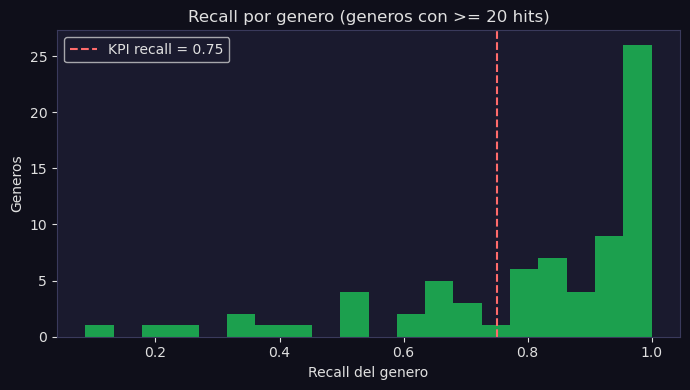

[graficos] Guardado: output\graficos\13_recall_por_genero.png


In [9]:
gr.grafico_recall_por_genero(elegibles)

### 4b. Recall por género sin filtrar
La tabla anterior solo incluye géneros con 20 o más hits, lo que excluye a los de pocos hits (los más difíciles). Aquí se usan **todos** los géneros con al menos un hit y se agrupan por hit rate del género. El recall "global" cuenta cada canción una vez por cada género al que pertenece, por eso difiere levemente del recall del modelo.

In [13]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pred = (p >= 0.5).astype(int)
d = (raw_test[["track_genre"]].assign(y=y_test.values, pred=pred)
     .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)

g = d.groupby("genero").agg(n=("y", "size"), hits=("y", "sum"), marcados=("pred", "sum"), tp=("tp", "sum"))
g["hit_rate_genero"] = g.hits / g.n
g["recall"] = g.tp / g.hits.where(g.hits > 0)
g["precision"] = g.tp / g.marcados.where(g.marcados > 0)

con_hits = g[g.hits > 0]
print(f"Géneros: {len(g)} | con al menos 1 hit en test (recall definido): {len(con_hits)} | sin hits: {(g.hits == 0).sum()}")
print(f"Recall macro (promedio de géneros): {con_hits.recall.mean():.3f} | recall global (por género-canción): {g.tp.sum() / g.hits.sum():.3f}")
print(f"Géneros con recall < 0.75 (KPI): {(con_hits.recall < 0.75).sum()} de {len(con_hits)} ({(con_hits.recall < 0.75).mean()*100:.0f}%)")
rho, _ = spearmanr(con_hits.hit_rate_genero, con_hits.recall)
print(f"Correlación (Spearman) entre hit rate del género y su recall: {rho:.2f}")

tramos = pd.cut(con_hits.hit_rate_genero, [0, 0.10, 0.25, 0.50, 1.0], include_lowest=True,
                labels=["bajo (<10%)", "medio (10-25%)", "alto (25-50%)", "muy alto (>50%)"])
res = con_hits.groupby(tramos, observed=True).agg(generos=("n", "size"), hits=("hits", "sum"), tp=("tp", "sum"),
                                                  marcados=("marcados", "sum"), n=("n", "sum"), recall_macro=("recall", "mean"))
res["recall_micro"] = res.tp / res.hits
res["precision_micro"] = res.tp / res.marcados
res["% marcadas como hit"] = res.marcados / res.n * 100
res[["generos", "hits", "recall_micro", "recall_macro", "precision_micro", "% marcadas como hit"]].round(3)

Géneros: 114 | con al menos 1 hit en test (recall definido): 109 | sin hits: 5
Recall macro (promedio de géneros): 0.580 | recall global (por género-canción): 0.846
Géneros con recall < 0.75 (KPI): 56 de 109 (51%)
Correlación (Spearman) entre hit rate del género y su recall: 0.94


,generos,hits,recall_micro,recall_macro,precision_micro,% marcadas como hit
hit_rate_genero,,,,,,
bajo (<10%),35,263,0.148,0.104,0.191,2.925
medio (10-25%),31,1148,0.661,0.625,0.287,42.295
alto (25-50%),33,2567,0.931,0.919,0.430,81.006
muy alto (>50%),10,1241,0.990,0.989,0.673,92.926


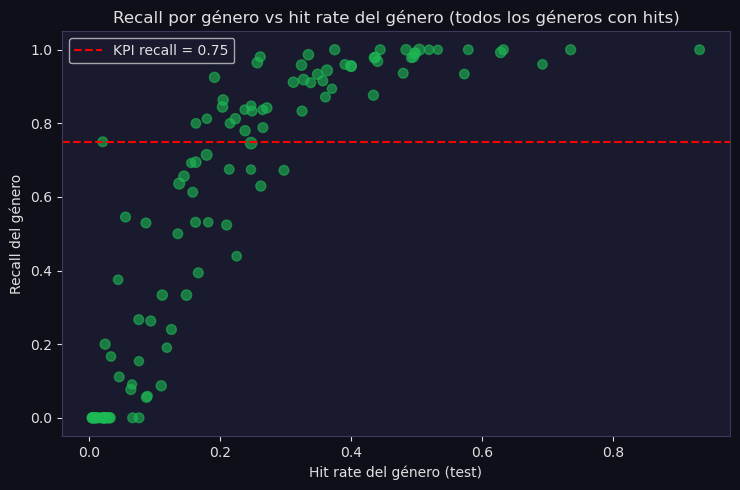

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(con_hits.hit_rate_genero, con_hits.recall, s=con_hits.n / 4, alpha=0.6, color="#1DB954")
ax.axhline(0.75, color="red", ls="--", label="KPI recall = 0.75")
ax.set_xlabel("Hit rate del género (test)"); ax.set_ylabel("Recall del género")
ax.set_title("Recall por género vs hit rate del género (todos los géneros con hits)"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join("output", "graficos", "16_recall_vs_hit_rate_genero.png"), dpi=120, bbox_inches="tight"); plt.show()

## 5. Importancia de variables (permutación)
Se permuta cada variable en test y se mide cuánto cae el AUC. Las columnas de género se permutan **juntas, como un solo bloque**: permutarlas una a una no tiene sentido porque cada una es solo un 0/1 de un género.

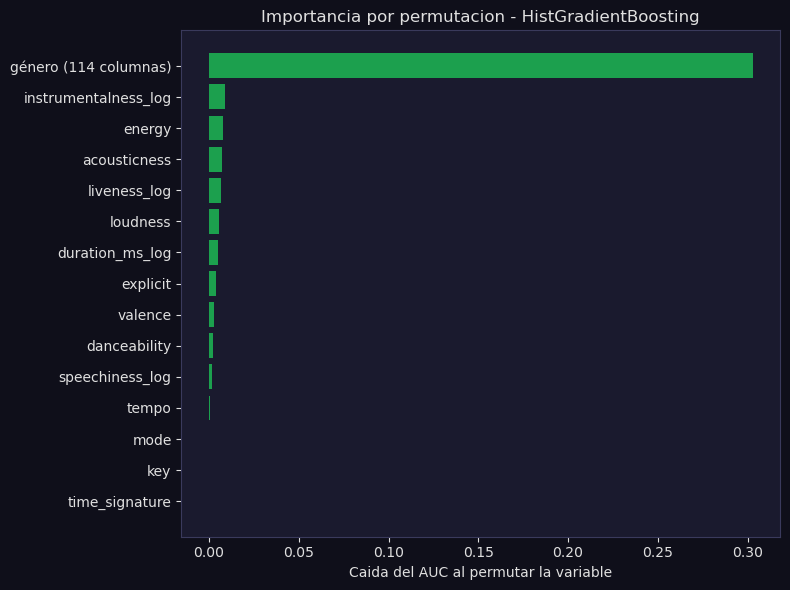

[graficos] Guardado: output\graficos\14_importancia_permutacion.png


,caída AUC
género (114 columnas),0.3029
instrumentalness_log,0.0091
energy,0.0076
acousticness,0.0070
liveness_log,0.0067


In [10]:
imp = gr.tabla_importancia_permutacion(m, X_test, y_test)
gr.grafico_importancia_permutacion(imp, mejor)
imp.sort_values(ascending=False).head(5).round(4).to_frame("caída AUC")

## 6. K-Means (no supervisado)
Se agrupan las canciones solo por sus variables de audio (sin género ni target) y luego se mira si los clusters se asocian con el hit rate.

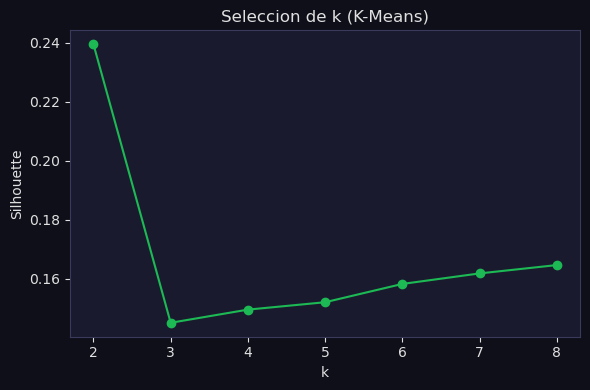

[graficos] Guardado: output\graficos\15_kmeans_silhouette.png
k elegido por silhouette: 2 (silhouette = 0.240)


In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

sc = StandardScaler().fit(X_train[FEATURES_SCALE])
Xk_tr, Xk_te = sc.transform(X_train[FEATURES_SCALE]), sc.transform(X_test[FEATURES_SCALE])

sil = gr.silhouette_kmeans(Xk_tr)
k_opt = gr.grafico_kmeans_silhouette(sil)
print(f"k elegido por silhouette: {k_opt} (silhouette = {sil[k_opt]:.3f})")

In [12]:
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(Xk_tr)
perfil = (X_test[["danceability", "energy", "acousticness", "valence", "loudness"]]
          .assign(cluster=km.predict(Xk_te), hit=y_test.values))
res_km = perfil.groupby("cluster").agg(n=("hit", "size"), hit_rate=("hit", "mean"),
                                       danceability=("danceability", "mean"), energy=("energy", "mean"),
                                       acousticness=("acousticness", "mean"), valence=("valence", "mean"),
                                       loudness=("loudness", "mean")).round(3)
print(f"Hit rate base en test: {y_test.mean():.3f}")
res_km

Hit rate base en test: 0.205


,n,hit_rate,danceability,energy,acousticness,valence,loudness
cluster,,,,,,,
0,4430,0.191,0.462,0.295,0.755,0.313,-14.664
1,13604,0.210,0.595,0.749,0.189,0.521,-6.446


## 7. Sensibilidad: split agrupado por artista
El split del pipeline agrupa por canción, y casi todo el test contiene artistas ya vistos en train. Aquí se re-divide train+test agrupando por **artista principal** (primer artista de la cadena), recalculando el P80 solo con el nuevo train, y se compara con la agrupación actual usando 3 semillas y los hiperparámetros del mejor modelo. Una colaboración puede seguir conectando artistas, por eso se reporta el % de test con artista visto.

In [15]:
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

# Pool = train + test originales (mismo orden que X_train / X_test); se re-divide con distintos criterios de agrupación
raw_train = pd.read_csv("data/raw/train/raw_train.csv")
pool_raw = pd.concat([raw_train, raw_test], ignore_index=True)
X_pool = pd.concat([X_train, X_test], ignore_index=True)
assert len(pool_raw) == len(X_pool)

pool_raw["artista_principal"] = pool_raw["artists"].str.split(";").str[0].str.strip().str.lower()

def solape_artistas(raw_tr, raw_te):
    """% de canciones de test con al menos un artista individual presente en train."""
    en_train = set(raw_tr["artists"].str.lower().str.split(";").explode().str.strip())
    return raw_te["artists"].str.lower().str.split(";").apply(lambda l: any(a.strip() in en_train for a in l)).mean()

def evaluar_split(grupos, semilla):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semilla)
    i_tr, i_te = next(gss.split(X_pool, groups=grupos))
    umbral_tr = pool_raw["popularity"].iloc[i_tr].quantile(0.80)             # P80 solo con el nuevo train
    y_all = (pool_raw["popularity"] >= umbral_tr).astype(int)
    mod = clone(modelos[mejor]).fit(X_pool.iloc[i_tr], y_all.iloc[i_tr])      # mismos hiperparámetros del mejor modelo
    p_s = mod.predict_proba(X_pool.iloc[i_te])[:, 1]
    yt, pred_s = y_all.iloc[i_te], (p_s >= 0.5).astype(int)
    k = int(len(yt) * 0.10)
    return {"AUC": roc_auc_score(yt, p_s), "PR-AUC": average_precision_score(yt, p_s),
            "Recall": recall_score(yt, pred_s), "Precision": precision_score(yt, pred_s),
            "Lift@10%": yt.values[np.argsort(-p_s)[:k]].mean() / yt.mean(),
            "% test con artista visto": solape_artistas(pool_raw.iloc[i_tr], pool_raw.iloc[i_te]) * 100}

filas = []
for semilla in (42, 43, 44):
    for nombre, grupos in (("Por canción (actual)", pool_raw["song_key"]),
                           ("Por artista principal", pool_raw["artista_principal"])):
        filas.append({"Agrupación": nombre, "semilla": semilla, **evaluar_split(grupos, semilla)})
sens = pd.DataFrame(filas)
print(f"Modelo evaluado: {mejor} | 3 semillas por criterio")
sens.drop(columns="semilla").groupby("Agrupación").agg(["mean", "std"]).round(4)

Modelo evaluado: HistGradientBoosting | 3 semillas por criterio


AUC          PR-AUC          Recall          \
                         mean     std    mean     std    mean     std   
Agrupación                                                              
Por artista principal  0.8451  0.0043  0.6047  0.0109  0.8119  0.0181   
Por canción (actual)   0.8562  0.0029  0.6222  0.0088  0.8319  0.0071   

                      Precision         Lift@10%          \
                           mean     std     mean     std   
Agrupación                                                 
Por artista principal    0.4251  0.0066   3.2267  0.0204   
Por canción (actual)     0.4218  0.0031   3.3634  0.0177   

                      % test con artista visto          
                                          mean     std  
Agrupación                                              
Por artista principal                  36.2673  2.0626  
Por canción (actual)                   91.6397  0.0753

## 8. Sensibilidad: excluir popularidad 0
La popularidad 0 se concentra en ciertos géneros y artistas y hoy cuenta como "no hit". Aquí se excluye de train **y** test, se recalcula el P80 solo con train y se compara con el escenario actual, con y sin las columnas de género (ablación: se anulan las columnas `genre_*`). Los dos escenarios usan conjuntos de test distintos y definiciones de hit distintas, por lo que los AUC no son estrictamente comparables; lo que importa es si el aporte del género cambia.

In [16]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, precision_score, recall_score, average_precision_score

genre_cols = [c for c in X_train.columns if c.startswith("genre_")]
y_train = pd.read_csv("data/processed/train/y_train.csv").squeeze()
raw_train = pd.read_csv("data/raw/train/raw_train.csv")

def sin_genero(X):
    """Ablación: se anulan las columnas de género (el modelo solo puede usar audio y metadatos)."""
    X = X.copy(); X[genre_cols] = 0
    return X

def ajustar_evaluar(Xtr, ytr, Xte, yte):
    mod = clone(modelos[mejor]).fit(Xtr, ytr)                 # mismos hiperparámetros del mejor modelo
    p_ = mod.predict_proba(Xte)[:, 1]
    pred_ = (p_ >= 0.5).astype(int)
    k = int(len(yte) * 0.10)
    return {"n test": len(yte), "hit rate test": float(np.mean(yte)),
            "AUC": roc_auc_score(yte, p_), "PR-AUC": average_precision_score(yte, p_),
            "Recall": recall_score(yte, pred_), "Precision": precision_score(yte, pred_),
            "Lift@10%": np.asarray(yte)[np.argsort(-p_)[:k]].mean() / np.mean(yte)}

# Escenario sin popularidad 0: se excluye de train Y de test y el P80 se recalcula solo con train
mask_tr = (raw_train["popularity"] > 0).values
mask_te = (raw_test["popularity"] > 0).values
print(f"Canciones con popularidad 0 excluidas -> train: {(~mask_tr).mean()*100:.1f}% | test: {(~mask_te).mean()*100:.1f}%")
umbral0 = raw_train.loc[mask_tr, "popularity"].quantile(0.80)
print(f"P80 sin popularidad 0 (train): {umbral0} (con popularidad 0: 52.0)")
y_tr0 = (raw_train.loc[mask_tr, "popularity"] >= umbral0).astype(int).values
y_te0 = (raw_test.loc[mask_te, "popularity"] >= umbral0).astype(int).values
Xtr0, Xte0 = X_train[mask_tr], X_test[mask_te]

filas = {
    "Actual (pop 0 = no hit) | con género":  ajustar_evaluar(X_train, y_train, X_test, y_test),
    "Actual (pop 0 = no hit) | solo audio":  ajustar_evaluar(sin_genero(X_train), y_train, sin_genero(X_test), y_test),
    "Sin popularidad 0       | con género":  ajustar_evaluar(Xtr0, y_tr0, Xte0, y_te0),
    "Sin popularidad 0       | solo audio":  ajustar_evaluar(sin_genero(Xtr0), y_tr0, sin_genero(Xte0), y_te0),
}
tabla_pop0 = pd.DataFrame(filas).T.round(4)
print(f"Aporte del género (AUC con género - solo audio): actual {tabla_pop0.iloc[0].AUC - tabla_pop0.iloc[1].AUC:+.3f} | "
      f"sin popularidad 0 {tabla_pop0.iloc[2].AUC - tabla_pop0.iloc[3].AUC:+.3f}")
tabla_pop0

Canciones con popularidad 0 excluidas -> train: 10.3% | test: 11.0%
P80 sin popularidad 0 (train): 54.0 (con popularidad 0: 52.0)
Aporte del género (AUC con género - solo audio): actual +0.164 | sin popularidad 0 +0.169


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Actual (pop 0 = no hit) | con género,18034.0,0.2053,0.8569,0.6193,0.8331,0.4254,3.3557
Actual (pop 0 = no hit) | solo audio,18034.0,0.2053,0.6932,0.3478,0.6869,0.3037,1.9642
Sin popularidad 0 | con género,16051.0,0.2024,0.8800,0.6672,0.8464,0.4527,3.6271
Sin popularidad 0 | solo audio,16051.0,0.2024,0.7107,0.3695,0.7054,0.3012,2.1861


## 9. Sensibilidad: target relativo al género
Si el género casi determina el hit, queda la duda de si el audio predice algo **dentro** de cada género. Aquí el hit se redefine como popularidad ≥ P80 **del género** (umbrales calculados solo con train; una canción con varios géneros usa el promedio de los umbrales de sus géneros). Con esta definición el hit rate es ≈ 20% en todos los géneros, así que el género deja de ser un predictor "gratis". Es un problema de negocio distinto ("¿será hit dentro de su género?") y se usa solo como prueba de sensibilidad. En géneros con muchos ceros el umbral es muy bajo, lo que vuelve ruidosa la etiqueta ahí.

In [17]:
from scipy.stats import spearmanr

gtr = raw_train[["track_genre", "popularity"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
umbral_genero = gtr.groupby("genero")["popularity"].quantile(0.80)
umbral_global = raw_train["popularity"].quantile(0.80)

def umbral_cancion(raw):
    e = raw[["track_genre"]].assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero")
    e["u"] = e["genero"].map(umbral_genero).fillna(umbral_global)          # género no visto -> umbral global
    return e.groupby(level=0)["u"].mean().reindex(raw.index).values

y_tr_rel = (raw_train["popularity"].values >= umbral_cancion(raw_train)).astype(int)
y_te_rel = (raw_test["popularity"].values >= umbral_cancion(raw_test)).astype(int)
print(f"Hit rate con target relativo -> train: {y_tr_rel.mean():.3f} | test: {y_te_rel.mean():.3f}")
print(f"Umbral P80 por género: mínimo {umbral_genero.min():.0f}, mediana {umbral_genero.median():.0f}, máximo {umbral_genero.max():.0f}")

res_rel = {
    "Target relativo | con género": ajustar_evaluar(X_train, y_tr_rel, X_test, y_te_rel),
    "Target relativo | solo audio": ajustar_evaluar(sin_genero(X_train), y_tr_rel, sin_genero(X_test), y_te_rel),
}
tabla_rel = pd.DataFrame(res_rel).T.round(4)
print(f"Aporte del género con target relativo (AUC con género - solo audio): {tabla_rel.iloc[0].AUC - tabla_rel.iloc[1].AUC:+.3f}")
tabla_rel

Hit rate con target relativo -> train: 0.198 | test: 0.198
Umbral P80 por género: mínimo 3, mediana 51, máximo 75
Aporte del género con target relativo (AUC con género - solo audio): +0.078


,n test,hit rate test,AUC,PR-AUC,Recall,Precision,Lift@10%
Target relativo | con género,18034.0,0.1981,0.6565,0.3304,0.6128,0.2735,1.8929
Target relativo | solo audio,18034.0,0.1981,0.5782,0.2552,0.5454,0.2335,1.4365


In [18]:
# ¿Se parejó el recall entre géneros? (modelo con género, target relativo, umbral 0.5)
mod_rel = clone(modelos[mejor]).fit(X_train, y_tr_rel)
pred_rel = (mod_rel.predict_proba(X_test)[:, 1] >= 0.5).astype(int)

def recall_por_genero(raw, y, pred):
    d = (raw[["track_genre"]].assign(y=np.asarray(y), pred=pred)
         .assign(genero=lambda x: x.track_genre.str.split("|")).explode("genero"))
    d["tp"] = ((d.y == 1) & (d.pred == 1)).astype(int)
    g = d.groupby("genero").agg(hits=("y", "sum"), tp=("tp", "sum"), n=("y", "size"), marcados=("pred", "sum"))
    g = g[g.hits > 0]
    g["recall"] = g.tp / g.hits
    g["hit_rate_genero"] = g.hits / g.n
    return g

g_abs = recall_por_genero(raw_test, y_test, (p >= 0.5).astype(int))   # target absoluto (modelo original)
g_rel = recall_por_genero(raw_test, y_te_rel, pred_rel)               # target relativo al género
comp = pd.DataFrame({
    "géneros con hits": [len(g_abs), len(g_rel)],
    "recall macro": [g_abs.recall.mean(), g_rel.recall.mean()],
    "desv. estándar del recall entre géneros": [g_abs.recall.std(), g_rel.recall.std()],
    "% géneros con recall < 0.75": [(g_abs.recall < 0.75).mean() * 100, (g_rel.recall < 0.75).mean() * 100],
    "Spearman (hit rate del género, recall)": [spearmanr(g_abs.hit_rate_genero, g_abs.recall)[0],
                                               spearmanr(g_rel.hit_rate_genero, g_rel.recall)[0]],
}, index=["Target absoluto (actual)", "Target relativo al género"]).round(3)
comp

,géneros con hits,recall macro,desv. estándar del recall entre géneros,% géneros con recall < 0.75,"Spearman (hit rate del género, recall)"
Target absoluto (actual),109,0.580,0.389,51.376,0.938
Target relativo al género,114,0.615,0.175,77.193,0.242


## Cómo leer estos resultados

- **KPIs:** el cumplimiento de AUC, gap, recall y lift está en la tabla de la sección 1. El recall se evalúa con umbral 0.5; la sección 2 muestra cómo cambia con otro umbral (con umbral 0.6 el F1 es el mejor, pero el recall deja de cumplir el KPI).
- **Selección del modelo:** el mejor modelo se elige por AUC de validación cruzada agrupada (`src/train.py`); el conjunto de test se usa solo para el reporte final.
- **Género:** sin género el AUC cae de 0.856 a 0.695 (sección 3) y el bloque de género domina la importancia por permutación (sección 5). Con solo audio no se llega al KPI de AUC.
- **Recall por género:** es muy desigual y crece con el hit rate del género (sección 4b, correlación de Spearman 0.94). En géneros de hit rate bajo el recall es ≈ 0.15 y el modelo marca solo ≈ 3% de las canciones; en géneros de hit rate muy alto el recall es ≈ 0.99 porque marca ≈ 93% de ellas. El recall global se sostiene por los géneros con muchos hits; el 51% de los géneros no llega al KPI de 0.75.
- **Artistas:** al agrupar el split por artista principal, el AUC baja ≈ 0.01 (0.856 → 0.845), el recall 0.832 → 0.812 y el lift 3.36 → 3.23 (sección 7). El optimismo por artistas repetidos existe pero es pequeño, y los KPIs se mantienen.
- **K-Means:** los clusters de audio separan estilos (acústico/tranquilo frente a enérgico) pero tienen un hit rate casi igual (0.19 frente a 0.21), de modo que el audio por sí solo aporta poca señal sobre el hit, lo que coincide con las correlaciones débiles del EDA.
- **Popularidad 0:** excluirla no reduce el aporte del género (+0.164 → +0.169 de AUC) y las métricas mejoran porque la etiqueta tiene menos ruido (sección 8). No explica el dominio del género; se mantiene como limitación documentada.
- **Target relativo al género:** al definir el hit dentro de cada género, el AUC baja a 0.66 con género y 0.58 solo con audio, y el recall se parece más entre géneros (desv. estándar 0.39 → 0.18), pero detecta peor en general (sección 9). Descontado el género, la señal del audio es modesta.